In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt

(x_train,y_train),(x_test,y_test)=tf.keras.datasets.cifar10.load_data()

x_train=x_train[:10000]/255.0
y_train=y_train[:10000]
x_test=x_test[:2000]/255.0
y_test=y_test[:2000]

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3334s 20us/step


In [3]:
def create_model():
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(32,32,3)),
        tf.keras.layers.Conv2D(32,3,activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64,3,activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dense(10,activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [4]:
model=create_model()
history=model.fit(x_train,y_train,epochs=3,batch_size=64,
                  validation_data=(x_test,y_test))

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.3151 - loss: 1.8885 - val_accuracy: 0.4190 - val_loss: 1.6327
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.4616 - loss: 1.5197 - val_accuracy: 0.4770 - val_loss: 1.5033
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.5143 - loss: 1.3614 - val_accuracy: 0.4925 - val_loss: 1.4494


In [5]:
loss,acc=model.evaluate(x_test,y_test)
print("Test Accuracy:",acc*100)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4925 - loss: 1.4494
Test Accuracy: 49.25000071525574


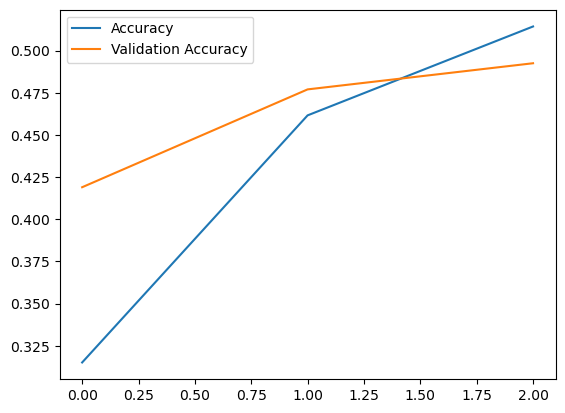

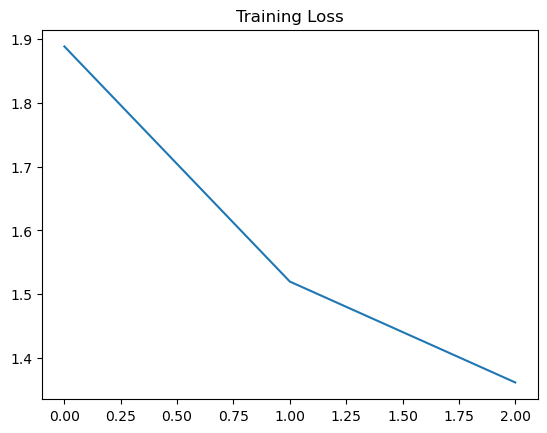

In [6]:
plt.plot(history.history['accuracy'],label='Accuracy')
plt.plot(history.history['val_accuracy'],label='Validation Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step


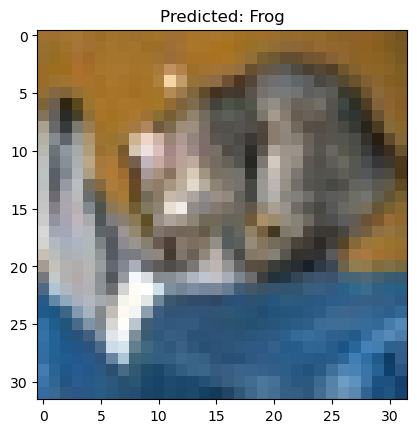

In [7]:
import numpy as np

classes=['Airplane','Car','Bird','Cat','Deer',
         'Dog','Frog','Horse','Ship','Truck']

i=0
pred=model.predict(x_test[i:i+1]).argmax()
plt.imshow(x_test[i])
plt.title("Predicted: "+classes[pred])
plt.show()